<a href="https://colab.research.google.com/github/Vineet55423/Ai_Breaker/blob/main/Linear_Regression_Problem_Insurance_charges_prediction_1st_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# importing essential libraries for the linear regression

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Machine learning related packages
# from statsmodels.stats.outliers_influence import variance_inflation_factor
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import *
# from sklearn.model_selection import GridSearchCV

**IMPORTING DATASET INTO DATAFRAME**

In [ ]:
df = pd.read_csv("/content/new_insurance_data.csv")

# EDA

In [ ]:
df.shape

(1338, 13)

In [ ]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'Claim_Amount',
       'past_consultations', 'num_of_steps', 'Hospital_expenditure',
       'NUmber_of_past_hospitalizations', 'Anual_Salary', 'region', 'charges'],
      dtype='object')

In [ ]:
df.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [ ]:
df.tail()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,170380500.5,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,201515184.8,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,223644981.3,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,252892382.6,3.0,4.006359e+09,southeast,62592.87309
1337,54.0,female,47.410,0.0,yes,63982.80926,31.0,1100328.0,261631699.3,3.0,4.117197e+09,southeast,63770.42801


In [ ]:
df.info() # float - 10, object - 3

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

In [ ]:
df.describe()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [ ]:
df.isna().sum().sum()

np.int64(52)

In [ ]:
df.isna().sum() # null present

,0
age,9
sex,0
bmi,3
children,5
smoker,0
Claim_Amount,14
past_consultations,6
num_of_steps,3
Hospital_expenditure,4
NUmber_of_past_hospitalizations,2


In [ ]:
df.duplicated().sum()

np.int64(0)

**Handling the null values**


if data has high and low jumps within data -> fill with **median**

if data is of categorical data -> fill with **mode**

if data is numeric + continuous or in nature normally distributed then with **mean**

In [ ]:
# approach one - fill null values using --> fillna("value", inplace = True)
# approach two - drop the null valus using dropna(inplace = True)

for x in df.columns:
  if df[x].dtype == 'object':

    df[x].fillna(df[x].mode()[0], inplace = True)

  else:
    df[x].fillna(df[x].mean(), inplace = True)

/tmp/ipykernel_723/3661454208.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[x].fillna(df[x].mean(), inplace = True)
/tmp/ipykernel_723/3661454208.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using '

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
Claim_Amount,0
past_consultations,0
num_of_steps,0
Hospital_expenditure,0
NUmber_of_past_hospitalizations,0


# chekcing the outliers


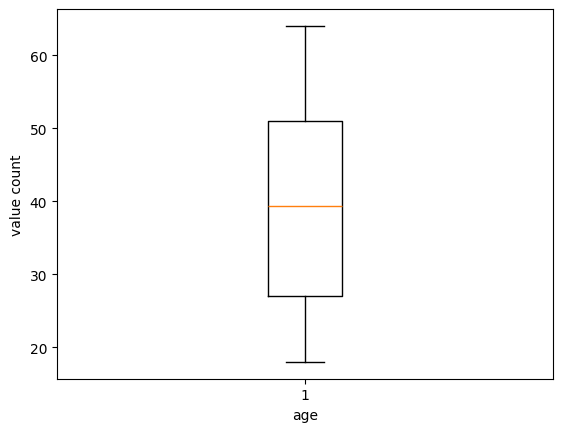

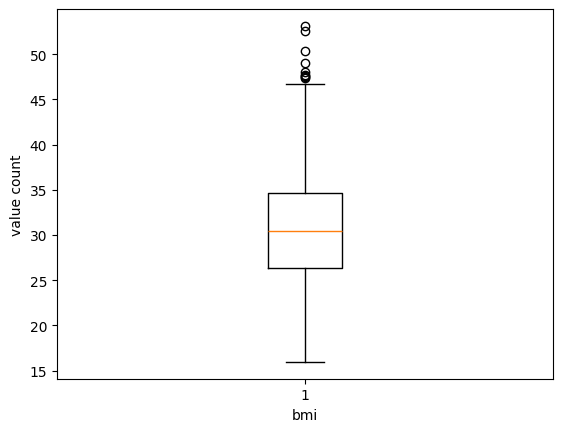

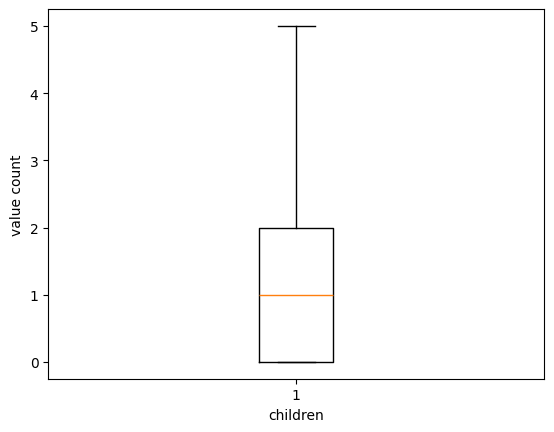

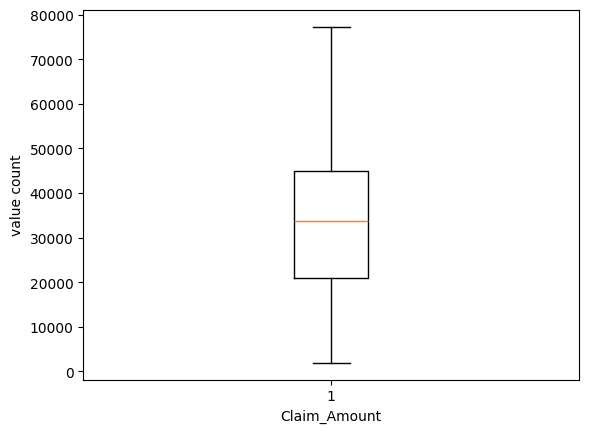

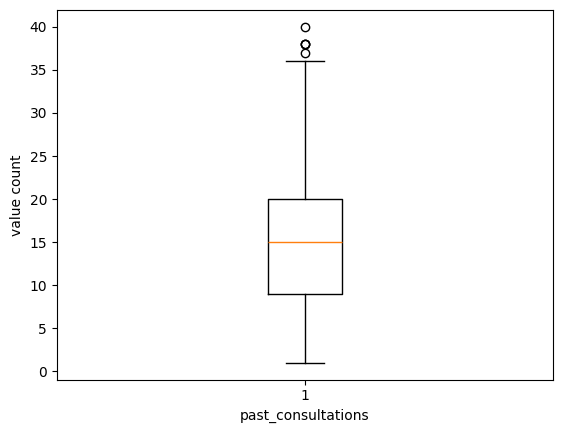

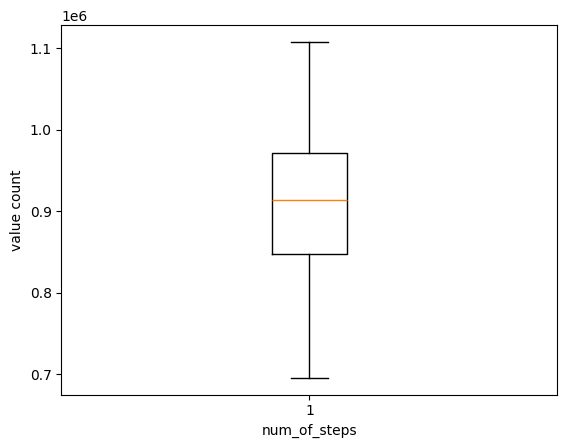

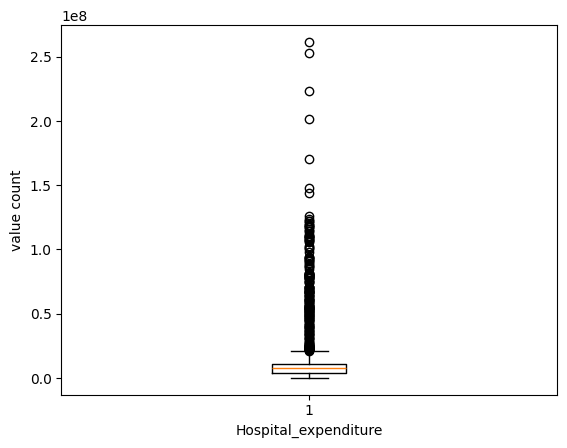

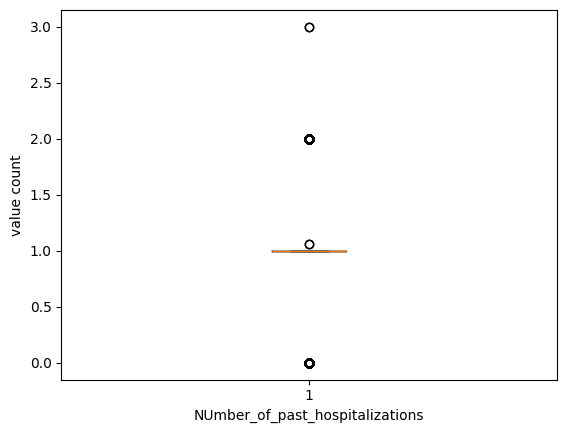

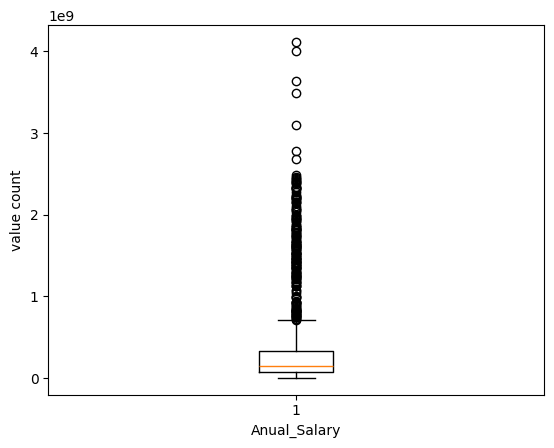

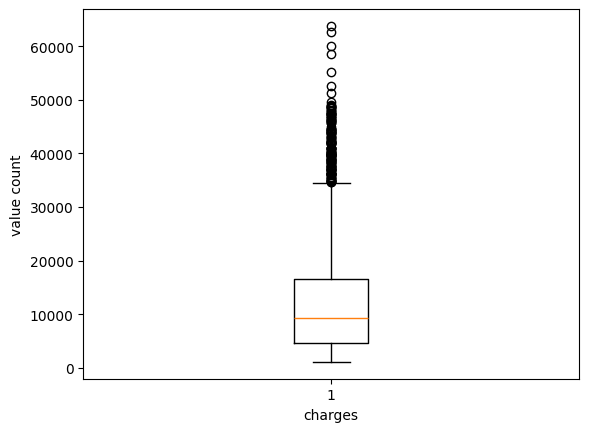

In [ ]:
for i in df.columns:
  if df[i].dtype != 'object':
    plt.boxplot(df[i])
    plt.xlabel(i)
    plt.ylabel("value count")
    plt.show()


**remove the outliers using IQR method**

In [ ]:
for x in df.columns:
  if df[x].dtype == 'object' or x == "charges":
    continue

  q1 = df[x].quantile(0.25)
  q3 = df[x].quantile(0.75)

  iqr = q3 - q1

  lb = q1 - 1.5 * iqr
  ub = q3 + 1.5 * iqr
  df = df[(df[x] >= lb) & (df[x] <= ub)]

check if outliers are removed or not: may be exist some outliers but there is no problem with that

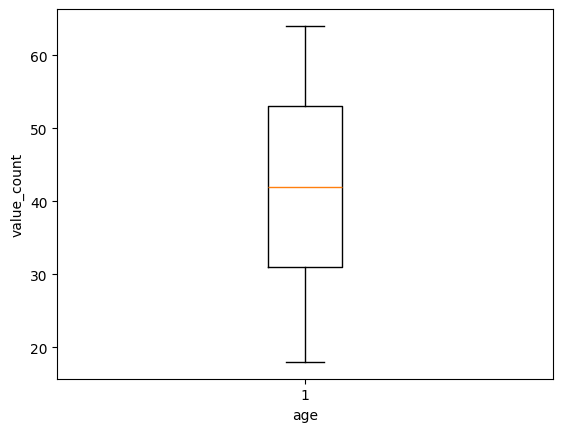

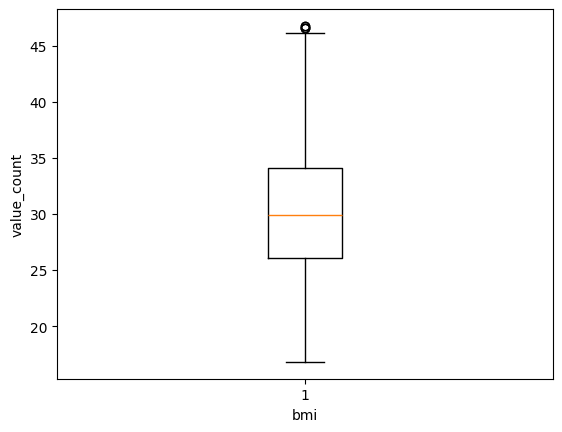

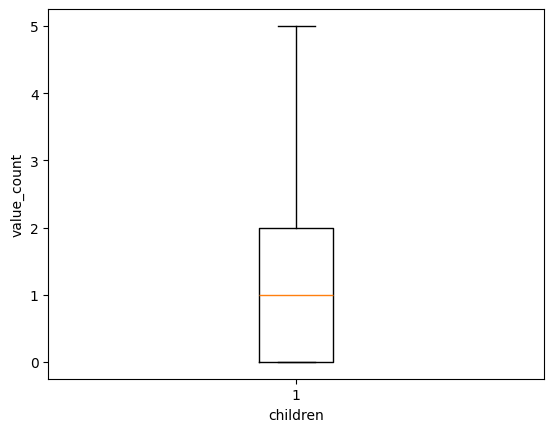

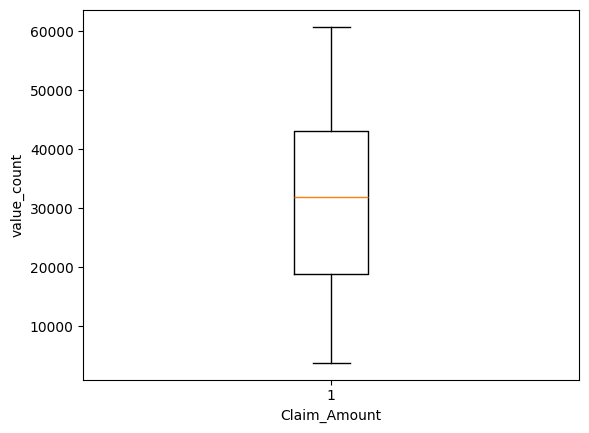

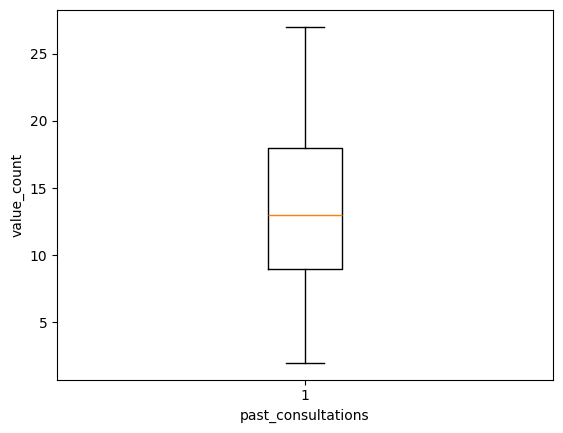

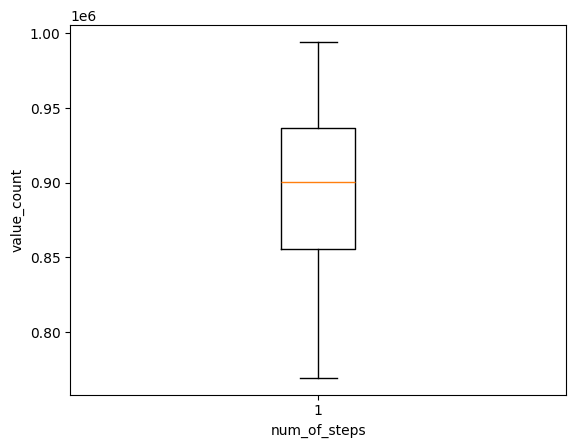

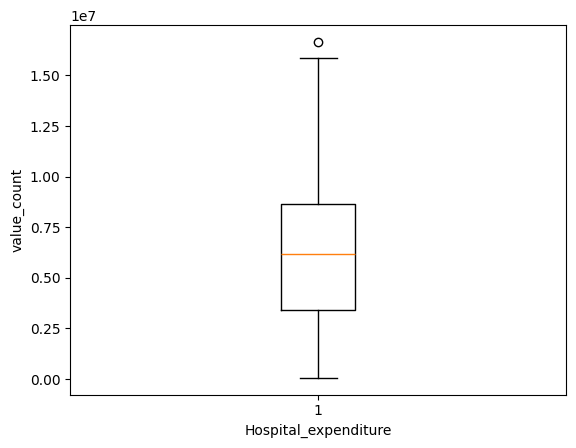

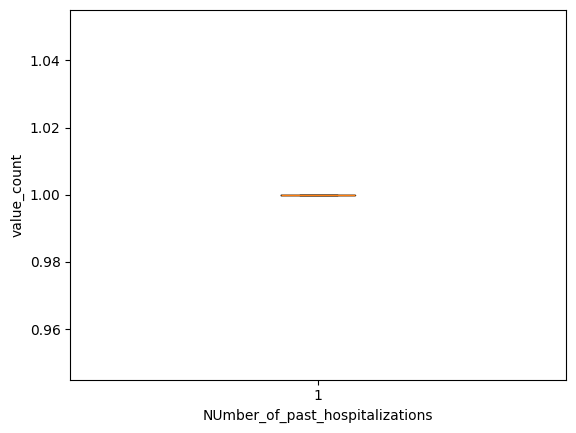

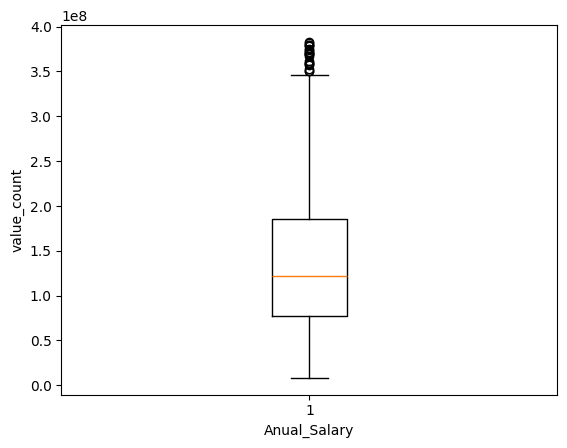

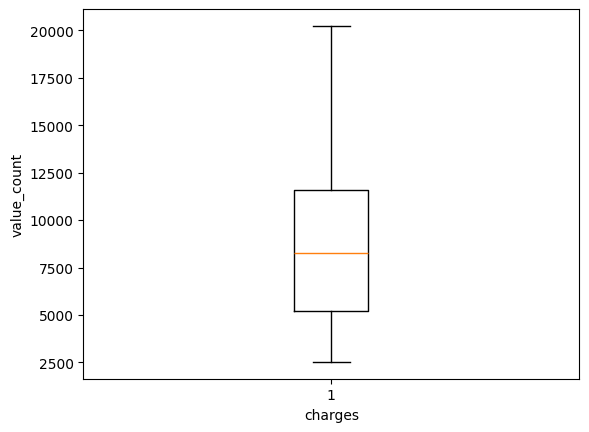

In [ ]:
for i in df.columns:
  if df[i].dtype != 'object':
    plt.boxplot(df[i])
    plt.xlabel(i)
    plt.ylabel("value_count")
    plt.show()

In [ ]:
df.shape

(881, 13)

**FEATURE SELECTION**

In [ ]:
# VIF = VARIANCE INFLATION FACTOR
# MULTICOLLINEARITY --> MULTIPLE COLUMNS ARE RELATED TO EACH OTHER STRONGLY

# VIF HELPS TO DETECT MULTICOLLINEARITY AMONG ALL INDEPENDENT FEATURES

# IF VIF > 5 --> HIGH MULTI COLLINAEARITY EXISTS ==== REMOVE THE COLUMN/FEATURE
# MULTICOLLINEARITY ONLY CHECKED FOR NUMERIC COLUMN

**fetching all numeric datatype columns in col_list** from df

In [ ]:
# COLLECT ALL THE INDEPENDENT NUMERIC COLUMN

col_list = []
for x in df.columns:
  if df[x].dtype != 'object' and x != 'charges':
    col_list.append(x)

col_list

['age',
 'bmi',
 'children',
 'Claim_Amount',
 'past_consultations',
 'num_of_steps',
 'Hospital_expenditure',
 'NUmber_of_past_hospitalizations',
 'Anual_Salary']

**importing vif from statsmodels.stats.outliers_infulience**

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

getting all those numeric data type columns of col_list in dummy and printing it

In [ ]:
dummy = df[col_list]
dummy

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary
151,25.0,27.550,0.0,39148.95495,10.0,780652.0,8.614147e+06,1.0,5.452601e+07
152,22.0,20.235,0.0,41547.52536,13.0,802627.0,2.491594e+05,1.0,1.671847e+07
153,25.0,35.625,0.0,39660.60193,12.0,770773.0,3.043323e+06,1.0,4.852694e+07
154,20.0,31.130,2.0,16032.87148,7.0,769255.0,1.599069e+06,1.0,2.441262e+07
155,21.0,17.400,1.0,31090.98977,21.0,778769.0,3.015365e+06,1.0,5.853579e+07
...,...,...,...,...,...,...,...,...,...
1046,29.0,27.940,1.0,51168.25474,23.0,993751.0,1.665982e+07,1.0,3.712188e+08
1048,31.0,25.900,3.0,46619.40230,27.0,989387.0,1.361938e+07,1.0,3.812895e+08
1050,31.0,29.810,0.0,24382.58056,21.0,973924.0,1.028991e+07,1.0,3.745310e+08
1062,43.0,20.045,2.0,21596.43846,10.0,994419.0,1.083030e+07,1.0,3.696849e+08


creating empty dataframe of name vif_data

we have to add two columns in vif_data i.e. feature and vif_value

In [ ]:
vif_data = pd.DataFrame()
vif_data['Feature'] = dummy.columns # dummy.columns = col_list

# empty list to fill with features values present in dummy for now
vif_list = []

for i in range(len(dummy.columns)):
  vif = variance_inflation_factor(dummy.values, i)
  vif_list.append(vif)

# filling second colomn of vif_value with vif_list got from above function logic
vif_data['vif_value'] = vif_list
vif_data

,Feature,vif_value
0,age,2.196194
1,bmi,1.052717
2,children,1.076523
3,Claim_Amount,1.035033
4,past_consultations,1.073989
5,num_of_steps,5.882074
6,Hospital_expenditure,1.173208
7,NUmber_of_past_hospitalizations,1.000000
8,Anual_Salary,3.983678


In [ ]:
# my all values are under 5, so no need to perform vif again and drop/delete any of the column

# if need to drop it, code is written below ( delete it from original dataset not in dummy)

# df = df.drop(["column name"], axis = 1)

# run it from col_list to vif_value calculation




# col_list = []
# for x in df.columns:
#   if df[x].dtype != 'object' and x != 'charges':
#     col_list.append(x)

# dummy = df[col_list]
# dummy

# vif_data = pd.DataFrame()
# vif_data['Feature'] = dummy.columns # dummy.columns = col_list

# # empty list to fill with features values present in dummy for now
# vif_list = []

# for i in range(len(dummy.columns)):
#   vif = variance_inflation_factor(dummy.values, i)
#   vif_list.append(vif)

# # filling second colomn of vif_value with vif_list got from above function logic
# vif_data['vif_value'] = vif_list

# vif_data

# Perform Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [ ]:
for x in df.columns:
  if df[x].dtypes == 'object':
    df[x] = le.fit_transform(df[x])


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 881 entries, 151 to 1069
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              881 non-null    float64
 1   sex                              881 non-null    int64  
 2   bmi                              881 non-null    float64
 3   children                         881 non-null    float64
 4   smoker                           881 non-null    int64  
 5   Claim_Amount                     881 non-null    float64
 6   past_consultations               881 non-null    float64
 7   num_of_steps                     881 non-null    float64
 8   Hospital_expenditure             881 non-null    float64
 9   NUmber_of_past_hospitalizations  881 non-null    float64
 10  Anual_Salary                     881 non-null    float64
 11  region                           881 non-null    int64  
 12  charges                 

In [ ]:
df

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
151,25.0,1,27.550,0.0,0,39148.95495,10.0,780652.0,8.614147e+06,1.0,5.452601e+07,1,2523.16950
152,22.0,0,20.235,0.0,0,41547.52536,13.0,802627.0,2.491594e+05,1.0,1.671847e+07,1,2527.81865
153,25.0,1,35.625,0.0,0,39660.60193,12.0,770773.0,3.043323e+06,1.0,4.852694e+07,1,2534.39375
154,20.0,1,31.130,2.0,0,16032.87148,7.0,769255.0,1.599069e+06,1.0,2.441262e+07,2,2566.47070
155,21.0,0,17.400,1.0,0,31090.98977,21.0,778769.0,3.015365e+06,1.0,5.853579e+07,3,2585.26900
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1046,29.0,0,27.940,1.0,1,51168.25474,23.0,993751.0,1.665982e+07,1.0,3.712188e+08,2,19107.77960
1048,31.0,1,25.900,3.0,1,46619.40230,27.0,989387.0,1.361938e+07,1.0,3.812895e+08,3,19199.94400
1050,31.0,1,29.810,0.0,1,24382.58056,21.0,973924.0,1.028991e+07,1.0,3.745310e+08,2,19350.36890
1062,43.0,0,20.045,2.0,1,21596.43846,10.0,994419.0,1.083030e+07,1.0,3.696849e+08,0,19798.05455


# **Model Building**

In [ ]:
# 1. Divide the data into x and y

x = df.iloc[:,: 12] # input columns -> independent feature
y = df.iloc[:,-1] # target column -> dependent feature

In [ ]:
x

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region
151,25.0,1,27.550,0.0,0,39148.95495,10.0,780652.0,8.614147e+06,1.0,5.452601e+07,1
152,22.0,0,20.235,0.0,0,41547.52536,13.0,802627.0,2.491594e+05,1.0,1.671847e+07,1
153,25.0,1,35.625,0.0,0,39660.60193,12.0,770773.0,3.043323e+06,1.0,4.852694e+07,1
154,20.0,1,31.130,2.0,0,16032.87148,7.0,769255.0,1.599069e+06,1.0,2.441262e+07,2
155,21.0,0,17.400,1.0,0,31090.98977,21.0,778769.0,3.015365e+06,1.0,5.853579e+07,3
...,...,...,...,...,...,...,...,...,...,...,...,...
1046,29.0,0,27.940,1.0,1,51168.25474,23.0,993751.0,1.665982e+07,1.0,3.712188e+08,2
1048,31.0,1,25.900,3.0,1,46619.40230,27.0,989387.0,1.361938e+07,1.0,3.812895e+08,3
1050,31.0,1,29.810,0.0,1,24382.58056,21.0,973924.0,1.028991e+07,1.0,3.745310e+08,2
1062,43.0,0,20.045,2.0,1,21596.43846,10.0,994419.0,1.083030e+07,1.0,3.696849e+08,0


In [ ]:
y

,charges
151,2523.16950
152,2527.81865
153,2534.39375
154,2566.47070
155,2585.26900
...,...
1046,19107.77960
1048,19199.94400
1050,19350.36890
1062,19798.05455


In [ ]:
# 2. Perform train-test split ( 80, 20)

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size = 0.8, random_state = 42)

In [ ]:
# 3. Model creation:

from sklearn.linear_model import LinearRegression

model = LinearRegression()


In [ ]:
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)
y_pred

array([ 7607.85080352,  5308.50427948,  9493.31042711, 11142.11548302,
        7177.46290601,  3162.24752057, 10130.3531249 , 13303.16888518,
        8599.14496062, 11971.4971193 , 12391.60209106, 12308.57988734,
        6074.84855493, 15108.92969082, 13528.02651336,  7984.76016645,
        6240.02537329,  7187.31088404,  8075.1834396 , 11911.07958654,
        8019.95879386,  1742.29810803,  7597.0023742 ,  1759.7024501 ,
        6684.04708442, 12676.42553721,  7366.28224082, 14058.52278458,
       11632.69299004,  7014.33187856,  9642.68306372,  3267.35636644,
        7828.96839265,  5055.90862348,  8297.26173924,  5815.33440369,
        2792.33801229, 10373.99286023,  6611.11488772,  2070.84957381,
        5819.98742891,  3574.34526225, 18529.57610284,  8941.22584014,
       11742.74695686,  4900.04298218, 12873.02532985,  7772.21386862,
        2975.38519267, 11871.09823443,  6261.18825847, 15106.80220452,
        9937.02441202,  4358.21273492, 15180.54205106,  7542.51468189,
      

# Check metrics of Linear regressoin

In [ ]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score : {r2:.4f}")
print(f"MAE      : {mae:.2f}")
print(f"RMSE     : {rmse:.2f}")

R² Score : 0.9689
MAE      : 590.98
RMSE     : 733.19


In [ ]:
# its almost 96% => a very good model